In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
import os
import sys
import glob
import uproot

def gaus(x, A, mean, sigma):
    return A * np.exp(-((x - mean)**2) / (2*(sigma)**2))

def sigmoid(x, mean, width):
    return 1.0 / (1 + np.exp(width * (x - mean)))

['../../Processed_data/proc_F_AC_LGAD_40um_strip_10db_attenuation_YaxisScan_NEv1000_BV115000mV_Laser95pc_Temp16C_Zpos42.4_Xpos40.9_Ypos105.000000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_10db_attenuation_YaxisScan_NEv1000_BV115000mV_Laser95pc_Temp16C_Zpos42.4_Xpos40.9_Ypos104.900000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_10db_attenuation_YaxisScan_NEv1000_BV115000mV_Laser95pc_Temp16C_Zpos42.4_Xpos40.9_Ypos104.100000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_10db_attenuation_YaxisScan_NEv1000_BV115000mV_Laser95pc_Temp16C_Zpos42.4_Xpos40.9_Ypos103.400000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_10db_attenuation_YaxisScan_NEv1000_BV115000mV_Laser95pc_Temp16C_Zpos42.4_Xpos40.9_Ypos105.100000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_10db_attenuation_YaxisScan_NEv1000_BV115000mV_Laser95pc_Temp16C_Zpos42.4_Xpos40.9_Ypos105.400000.root', '../../Processed_data/proc_F_AC_LGAD_40um_strip_10db_attenuation_YaxisScan_NEv1000_BV11

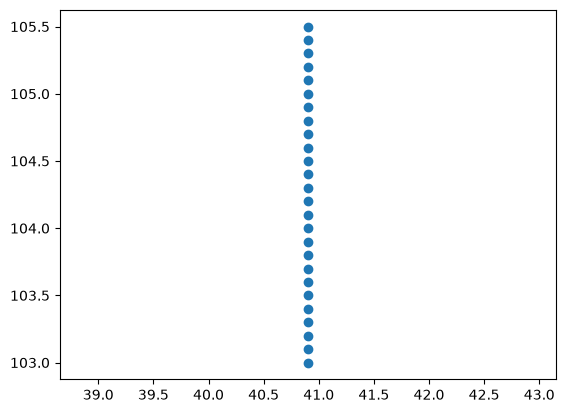

In [8]:
path = "../../Processed_data/"
files = glob.glob(f"{path}proc_F_AC_LGAD_40um_strip_10db_attenuation_YaxisScan_NEv1000_BV115000mV_Laser95pc_Temp16C_Zpos*_Xpos*_Ypos*00000.root")

print(files)
Z_range = [] # [41.5] # np.linspace(50.0, 50.8, 11)
X_range = [] # np.linspace(41.4, 41.7, 11)
Y_range = [] # np.linspace(41.4, 41.7, 11)

map_plot_y = []
map_plot_x = []
map_plot_z = []

y_files = []

for file in files:
    filename = file.split(path)[1]

    if "Ypos" not in filename or "Zpos" not in filename or "Xpos" not in filename: 
        continue
    
    print(filename)
    y_files.append(file)
    # x_pos = np.round(float(filename.split("Xpos")[1].split("00000.root")[0]), 3)
    # x_pos = np.round(float(filename.split("Xpos")[1].split("00000.trc")[0]), 3)
    # z_pos = np.round(float(filename.split("Zpos")[1].split("_")[0])        , 3)
    
    x_pos = float(filename.split("Xpos")[1].split("_")[0])
    y_pos = float(filename.split("Ypos")[1].split("00000.root")[0])
    # x_pos = float(filename.split("Xpos")[1].split("00000.trc")[0])
    z_pos = float(filename.split("Zpos")[1].split("_")[0])

    if z_pos < 40.0 and z_pos > 43.9: continue
    
    X_range.append(float(x_pos))
    Y_range.append(float(y_pos))
    Z_range.append(float(z_pos))
    map_plot_x.append(x_pos)
    map_plot_y.append(y_pos)
    map_plot_z.append(z_pos)

Z_range = np.unique(Z_range)
X_range = np.unique(X_range)
# map_plot_x = np.sort(map_plot_x)
# map_plot_z = np.sort(map_plot_z)

plt.scatter(map_plot_x, map_plot_y)
plt.show()

fields = [
    'i_evt',
    # 'channel',
    # 'time',
    # 'baseline',
    'baseline_RMS',
    'noise',
    'amp',
    # 't_peak',
    'integral',
    # 'intfull',
    # 'risetime',
    # 'decaytime',
    # 'LP2_5',
    # 'LP2_10',
    # 'LP2_15',
    # 'LP2_20',
    # 'LP2_25',
    # 'LP2_30',
    # 'LP2_35',
    # 'LP2_40',
    # 'LP2_45',
    'LP2_50',
    # 'LP2_55',
    # 'LP2_60',
    # 'LP2_65',
    # 'LP2_70',
    # 'LP2_75',
    # 'LP2_80',
    # 'LP2_85',
    # 'LP2_90',
    # 'LP2_95',
    # 'LP2_100',
    # 'LP2_10mV',
    # 'LP2_20mV',
    # 'LP2_30mV',
    # 'LP2_50mV',
    # 'LP2_70mV',
    # 'LP2_90mV',
    # 'LP2_100mV',
    # 'LP2_120mV',
    # 'LP2_140mV',
    # 'LP2_160mV',
    # 'LP2_180mV',
    # 'LP2_200mV',
    # 'linear_RE_5',
    # 'linear_RE_10',
    # 'linear_RE_15',
    # 'linear_RE_20',
    # 'linear_RE_25',
    # 'linear_RE_30',
    # 'linear_RE_35',
    # 'linear_RE_40',
    # 'linear_RE_45',
    # 'linear_RE_50',
    # 'linear_RE_55',
    # 'linear_RE_60',
    # 'linear_RE_65',
    # 'linear_RE_70',
    # 'linear_RE_75',
    # 'linear_RE_80',
    # 'linear_RE_85',
    # 'linear_RE_90',
    # 'linear_RE_95',
    # 'linear_RE_100',
    # 'linear_RE__10mV',
    # 'linear_RE__20mV',
    # 'linear_RE__30mV',
    # 'linear_RE__50mV',
    # 'linear_RE__70mV',
    # 'linear_RE__90mV',
    # 'linear_RE__100mV',
    # 'linear_RE__120mV',
    # 'linear_RE__140mV',
    # 'linear_RE__160mV',
    # 'linear_RE__180mV',
    # 'linear_RE__200mV'
]
    

In [9]:
integral = {}
amp = {}
t_peak = {}
risetime = {}
timestamps = {}
baseline_RMS = {}
risetime = {}
channel = {}
time = {}

for f_i, f in enumerate(y_files):
    # if map_plot_z[f_i] > 50: continue
    pulse = uproot.open(f)["pulse"].arrays(fields)
    l = f"pos_{map_plot_z[f_i]}_{map_plot_x[f_i]}_{map_plot_y[f_i]}"
    # channel[l] = pulse["channel"]
    # time[l] = pulse["time"]
    integral[l] = pulse["integral"]
    # risetime[l] = pulse["risetime"]
    amp[l] = pulse["amp"]
    baseline_RMS[l] = pulse["baseline_RMS"]
    timestamps[l] = pulse["LP2_50"]
    del pulse

print(amp.keys())

dict_keys(['pos_42.4_40.9_105.0', 'pos_42.4_40.9_104.9', 'pos_42.4_40.9_104.1', 'pos_42.4_40.9_103.4', 'pos_42.4_40.9_105.1', 'pos_42.4_40.9_105.4', 'pos_42.4_40.9_104.6', 'pos_42.4_40.9_104.3', 'pos_42.4_40.9_103.1', 'pos_42.4_40.9_104.2', 'pos_42.4_40.9_105.3', 'pos_42.4_40.9_105.5', 'pos_42.4_40.9_105.2', 'pos_42.4_40.9_103.6', 'pos_42.4_40.9_104.8', 'pos_42.4_40.9_104.7', 'pos_42.4_40.9_103.0', 'pos_42.4_40.9_103.3', 'pos_42.4_40.9_103.5', 'pos_42.4_40.9_104.4', 'pos_42.4_40.9_103.9', 'pos_42.4_40.9_104.0', 'pos_42.4_40.9_104.5', 'pos_42.4_40.9_103.8', 'pos_42.4_40.9_103.2', 'pos_42.4_40.9_103.7'])


[42.4]


rm: cannot remove './TimestampFits/*': No such file or directory
rm: cannot remove './AmplitudeFits/*': No such file or directory


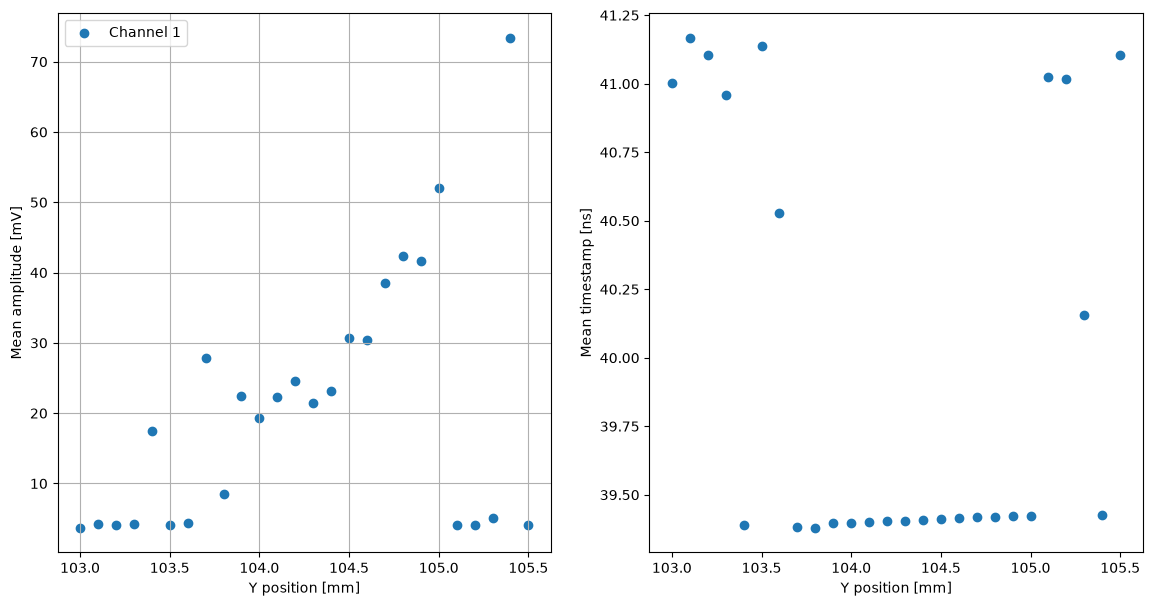

In [16]:
plot_size = 7

def fit_gaus(hist, tag, output_folder, value_tag, plot_fits = True):
    nbins = 20
    y, x = np.histogram(hist, bins=nbins)
    x = np.array(x)
    y = np.array(y)

    hist = hist[hist != 0]

    # print(np.sum(hist != 0))
    
    mean = x[np.argmax(y)] # 
    mean = np.mean(hist)
    std  = np.std(hist)

    mask = np.ones(len(hist), dtype = bool)
    mask = (hist>(mean-3*std)) & (hist<(mean+3*std))
    
    # print(np.sum(hist != 0))
    # print()
    
    std  = np.std(hist[mask])
    mean = np.mean(hist[mask])
    y, x = np.histogram(hist[mask], bins=nbins)
    x = np.array(x)
    y = np.array(y)

    if (np.sum(mask) == 0):
        print("Discarding this fit -----------> ", mean, std)
        return 0, 0, 0

    percentage = 50
    # bounds = (
    #     ((1-percentage / 100)*np.max(y), (1-percentage / 100)*np.mean(hist[mask]), (1-percentage / 100)*np.std(hist[mask]) ),
    #     ((1+percentage / 100)*np.max(y), (1+percentage / 100)*np.mean(hist[mask]), (1+percentage / 100)*np.std(hist[mask]) )
    # )

    bounds = (
        ( (0)*np.max(y), (1-percentage / 100)*np.mean(hist[mask]), (1-percentage / 100)*np.std(hist[mask]) ),
        ( (2)*np.max(y), (1+percentage / 100)*np.mean(hist[mask]), (1+percentage / 100)*np.std(hist[mask]) )
    )
    
    # print(x[0:nbins], y[0:nbins])
    # try:
    #     params = curve_fit(gaus, x[0:nbins], y[0:nbins], p0=( np.max(y), np.mean(x), std)) # , bounds = bounds) # , p0=( np.mean(y), mean, np.std(hist[mask]) ) )
    #     if (plot_fits):
    #         y_fit = [gaus(i, params[0][0], params[0][1], params[0][2]) for i in x[0:nbins]]
    #         # print(x[0:nbins])
    #         # print(y_fit)
    #         fig, ax = plt.subplots(1, 1, figsize = (plot_size, plot_size))
    #         ax.hist(hist[mask], bins = nbins, histtype="step")
    #         ax.plot([mean, mean], [0, np.max(y)], color = "black")
    #         ax.plot([params[0][1]-params[0][2], params[0][1]+params[0][2]], [np.max(y)/2, np.max(y)/2], color = "black")
    #         ax.plot(x[0:nbins], y_fit, "o", color = "red", label = f"Amplitude: {np.round(params[0][0],3)}, Mean: {np.round(params[0][1],3)}, Sigma: {np.round(params[0][2],3)}")
    #         ax.set_xlabel(value_tag) # "Timestamps [ns]")
    #         ax.set_ylabel("Number of events")
    #         plt.legend()
    #         fig.savefig(f"./{output_folder}/{tag}.png")
    #         return params[0][0], params[0][1], params[0][2]

    # except:
    #     if (plot_fits):
    #         fig, ax = plt.subplots(1, 1, figsize = (plot_size, plot_size))
    #         ax.hist(hist[mask], bins = nbins, histtype="step")
    #         ax.set_xlabel(value_tag)
    #         ax.set_ylabel("Number of events")
    #         plt.legend()
    #         # plt.show()
    #         fig.savefig(f"./{output_folder}/{tag}.png")
    #         return 0, 0, 0
    
    # params = curve_fit(gaus, x[0:nbins], y[0:nbins], p0=( np.max(y), np.mean(x), std ), bounds = bounds) # , p0=( np.mean(y), mean, np.std(hist[mask]) ) )
    # print("Parameters     ----------------> ", mean, std)
    # print("Fit parameters ----------------> ", params[0][1], params[0][2])
    # print()
    return np.max(y), mean, std 

cols = 2
rows = 1

strip_index = 0

fig, ax = plt.subplots(rows, cols, figsize = (plot_size*cols, plot_size*rows))
# Z_range = [50.0, 50.8]
print(Z_range)

os.system("rm ./TimestampFits/*")
os.system("rm ./AmplitudeFits/*")

for z_i, z in enumerate(Z_range):

    mean_amps_0 = []
    mean_amps_0_err = []
    mean_amps_1 = []
    mean_amps_1_err = []
    mean_amps_2 = []
    mean_amps_2_err = []
    mean_amps_3 = []
    mean_amps_3_err = []

    mean_time_0 = []
    mean_time_0_err = []
    mean_time_1 = []
    mean_time_1_err = []
    mean_time_2 = []
    mean_time_2_err = []
    mean_time_3 = []
    mean_time_3_err = []

    n_events_0 = []
    n_events_1 = []
    for x_i, x in enumerate(X_range):
        for y_i, y in enumerate(Y_range):
            # l = f"pos_{map_plot_z[z_i]}_{map_plot_x[x_i]}"
            l = f"pos_{z}_{x}_{y}"

            # if (np.sum(timestamps[l][:,0]>0) > 0):
            # print(l)
            # print("len(amp[l][:,0]): ", len(timestamps[l][:,0]))
            
            if (np.sum(timestamps[l][:,1]>0) > 0):
                fit_time_A, fit_time_mean, fit_time_sigma = fit_gaus(timestamps[l][:,0], l+"_ch0", "TimestampFits", "Timestamp [ns]", True)
                mean_time_0    .append(fit_time_mean)
                mean_time_0_err.append(fit_time_sigma)
                
                fit_amp_A, fit_amp_mean, fit_amp_sigma = fit_gaus(amp[l][:,0], l+"_ch0", "AmplitudeFits", "Amplitude [mV]", True)
                mean_amps_0    .append(fit_amp_mean)
                mean_amps_0_err.append(fit_amp_sigma)
            else:
                mean_amps_0    .append(0)
                mean_amps_0_err.append(0)
                mean_time_0    .append(0)
                mean_time_0_err.append(0)
            
            if (np.sum(timestamps[l][:,1]>0) > 0):
                # print(l)
                # print("len(amp[l][:,1]): ", len(timestamps[l][:,1]))
                
                fit_time_A, fit_time_mean, fit_time_sigma = fit_gaus(timestamps[l][:,1], l+"_ch1", "TimestampFits", "Timestamp [ns]", True)
                mean_time_1    .append(fit_time_mean)
                mean_time_1_err.append(fit_time_sigma)
                
                fit_amp_A, fit_amp_mean, fit_amp_sigma = fit_gaus(amp[l][:,1], l+"_ch1", "AmplitudeFits", "Amplitude [mV]", True)
                mean_amps_1    .append(fit_amp_mean)
                mean_amps_1_err.append(fit_amp_sigma)
            
            else:
                mean_amps_1    .append(0)
                mean_amps_1_err.append(0)
                mean_time_1    .append(0)
                mean_time_1_err.append(0)

            if (np.sum(timestamps[l][:,2]>0) > 0):
                # print(l)
                # print("len(amp[l][:,2]): ", len(timestamps[l][:,2]))
                
                fit_time_A, fit_time_mean, fit_time_sigma = fit_gaus(timestamps[l][:,2], l+"_ch2", "TimestampFits", "Timestamp [ns]", True)
                mean_time_2    .append(fit_time_mean)
                mean_time_2_err.append(fit_time_sigma)
                
                fit_amp_A, fit_amp_mean, fit_amp_sigma = fit_gaus(amp[l][:,2], l+"_ch2", "AmplitudeFits", "Amplitude [mV]", True)
                mean_amps_2    .append(fit_amp_mean)
                mean_amps_2_err.append(fit_amp_sigma)
            
            else:
                mean_amps_2    .append(0)
                mean_amps_2_err.append(0)
                mean_time_2    .append(0)
                mean_time_2_err.append(0)

            if (np.sum(timestamps[l][:,3]>0) > 0):
                # print(l)
                # print("len(amp[l][:,3]): ", len(timestamps[l][:,3]))
                
                fit_time_A, fit_time_mean, fit_time_sigma = fit_gaus(timestamps[l][:,3], l+"_ch3", "TimestampFits", "Timestamp [ns]", True)
                mean_time_3    .append(fit_time_mean)
                mean_time_3_err.append(fit_time_sigma)
                
                fit_amp_A, fit_amp_mean, fit_amp_sigma = fit_gaus(amp[l][:,3], l+"_ch3", "AmplitudeFits", "Amplitude [mV]", True)
                mean_amps_3    .append(fit_amp_mean)
                mean_amps_3_err.append(fit_amp_sigma)
            else:
                mean_amps_3    .append(0)
                mean_amps_3_err.append(0)
                mean_time_3    .append(0)
                mean_time_3_err.append(0)

            # if (len(timestamps[l][:,1])!=0):
            #     print(l)
            #     print("len(amp[l][:,1]): ", len(timestamps[l][:,1]))
            #     A, mean, sigma = fit_gaus(timestamps[l][:,1], l+"_ch1")
            #     mean_amps_1.append(mean)
            #     mean_amps_1_err.append(sigma)
            # else:
            #     mean_amps_1.append(0)
            #     mean_amps_1_err.append(0)
                
            # if (len(timestamps[l][:,2])!=0):
            #     print(l)
            #     print("len(amp[l][:,2]): ", len(timestamps[l][:,2]))
            #     A, mean, sigma = fit_gaus(timestamps[l][:,2], l+"_ch2")
            #     mean_amps_2.append(mean)
            #     mean_amps_2_err.append(sigma)
            # else:
            # mean_amps_2.append(0)
            # mean_amps_2_err.append(0)
            # if (len(timestamps[l][:,3])!=0):
            #     print(l)
            #     print("len(amp[l][:,3]): ", len(timestamps[l][:,3]))
            #     A, mean, sigma = fit_gaus(timestamps[l][:,3], l+"_ch3")
            #     mean_amps_3.append(mean)
            #     mean_amps_3_err.append(sigma)
            # else:
            # mean_amps_3.append(0)
            # mean_amps_3_err.append(0)
            
            # print()
        
        sorting = np.argsort(Y_range)
        mean_amps_0 = np.array(mean_amps_0)[sorting]
        # mean_amps_1 = np.array(mean_amps_1)[sorting]
        # mean_amps_2 = np.array(mean_amps_2)[sorting]
        # mean_amps_3 = np.array(mean_amps_3)[sorting]
        mean_amps_0_err = np.array(mean_amps_0_err)[sorting]
        # mean_amps_1_err = np.array(mean_amps_1_err)[sorting]
        # mean_amps_2_err = np.array(mean_amps_2_err)[sorting]
        # mean_amps_3_err = np.array(mean_amps_3_err)[sorting]

        mean_time_0 = np.array(mean_time_0)[sorting]
        # mean_time_1 = np.array(mean_time_1)[sorting]
        # mean_time_2 = np.array(mean_time_2)[sorting]
        # mean_time_3 = np.array(mean_time_3)[sorting]
        mean_time_0_err = np.array(mean_time_0_err)[sorting]
        # mean_time_1_err = np.array(mean_time_1_err)[sorting]
        # mean_time_2_err = np.array(mean_time_2_err)[sorting]
        # mean_time_3_err = np.array(mean_time_3_err)[sorting]

        Y_range = np.array(Y_range)
        Y_range = Y_range[sorting]

        n_events_0 = np.array(n_events_0)
        n_events_1 = np.array(n_events_1)

        # print(X_range[mean_amps != 0])
        # print(mean_amps[mean_amps != 0])
        marker_size = 5

        ax[0].scatter(Y_range, mean_amps_0, label = "Channel 1", marker= "o") # f"Z position: {z}")
        ax[1].scatter(Y_range, mean_time_0, label = "Channel 1", marker= "o") # f"Z position: {z}")       

        # ax[0].errorbar(Z_range, mean_amps_0, mean_amps_0_err, label = "Channel 3", marker= "o") # f"Z position: {z}")
        # ax[1].errorbar(Z_range, mean_time_0, mean_time_0_err, label = "Channel 3", marker= "o") # f"Z position: {z}")
                
        ax[1].set_xlabel("Y position [mm]")
        ax[1].set_ylabel("Mean timestamp [ns]")
        # ax[1].set_ylim(0, 200)
        # ax[1].set_xlim(103.8, 104.6)

        ax[0].set_xlabel("Y position [mm]")
        ax[0].set_ylabel("Mean amplitude [mV]")
        # ax[0].set_ylim(0, 200)
        # ax[0].set_xlim(103.8, 104.6)

ax[0].grid()
ax[0].legend()
plt.show()

In [17]:
print(len(X_range), len(mean_amps_0), len(mean_amps_0_err))

1 26 26


26 26
[1.30559082 1.52969888 1.50520522 1.4623186  1.3102247  1.50877675
 1.49088848 1.17459008 1.33909554 1.21759148 1.28081707 1.24812689
 1.1972954  1.25659883 1.23524114 1.12104696 1.10633612 0.97062238
 0.95309433 0.89781061 0.41764755 1.46770382 1.4899631  1.43277164
 0.24902435 1.43767841]


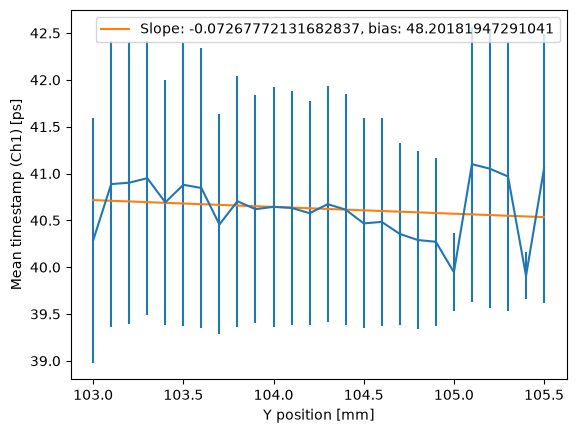

In [18]:
def line(x, p1, p2):
    return x*p1 + p2

def pol_2(x, p1, p2, p3):
    return p1*x**2 + p2*x + p3

def pol_3(x, p1, p2, p3, p4):
    return p1*x**3 + p2*x**2 + p3*x + p4

print(len(Y_range), len(mean_time_0))

mask = np.ones(len(Y_range), dtype = bool) # ((Y_range>103.5) & (Y_range<104.6))
mean_time_0 = np.array(mean_time_0)

MT = np.array(mean_time_0)
MT_err = np.array(mean_time_0_err)

MT = np.array(mean_time_1)
MT_err = np.array(mean_time_1_err)

MT = np.array(mean_time_2)
MT_err = np.array(mean_time_2_err)

MT = np.array(mean_time_3)
MT_err = np.array(mean_time_3_err)

t0 = MT[mask][0]
t0_err = MT_err[mask][0]
dt = []
dt_err = []
for i, t in enumerate(MT):
    
    dt    .append(         (t )) # - t0)*1000                )
    dt_err.append(np.sqrt( MT_err[i]**2 )) #  + t0_err**2 ))
    
    # print(np.round(Y_range[i], 4), t - t0)

Y_range = np.array(Y_range)
dt = np.array(dt)
dt_err = np.array(dt_err)

print(dt_err)

mask = ((Y_range>0) & (Y_range<110)) # ((Y_range>103.6) & (Y_range<104.6))
params = curve_fit(line, Y_range[mask], dt[mask])

fitted_dt = np.array([line(y, params[0][0], params[0][1]) for y in Y_range])
plt.errorbar(Y_range[mask], dt[mask], dt_err[mask])
# plt.plot(Y_range[mask], dt[mask]) # , dt_err[mask])
plt.plot(Y_range[mask], fitted_dt[mask], label = f"Slope: {params[0][0]}, bias: {params[0][1]}")
plt.xlim()
plt.legend()
plt.xlabel("Y position [mm]")
plt.ylabel("Mean timestamp (Ch1) [ps]")
plt.show()